# 03 - 2023 DNN, trained centrally on the honest pipeline (step 7)

This notebook **only calls** `baseline_2023.fl2023`; training lives in `our_work/baseline_2023/fl2023.py` and was run with
`python -m baseline_2023.fl2023` (3 seeds), which logs to `baseline_2023/results/results.jsonl`. Here we show the model, the
training curves, the test results and the confusion matrix.

**Setup:** honest pipeline (36 features, held-out test set, one global scaler), 1:1 balanced training rows, Adam (lr 0.01, eps 1e-7),
batch 1024, 100 epochs, Keras-style initialisation. The checkpoint with the best **validation AUC** is kept, the decision threshold
maximising F1 is chosen on the **validation** set only, and the test set is scored **once** per seed. No federation, no differential privacy.

In [1]:
import sys, pathlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200, "display.max_columns", 30)
ROOT = pathlib.Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent                      # our_work/
sys.path.insert(0, str(ROOT))
from baseline_2023.fl2023 import make_model, model_summary, load_central, METRIC_COLS, MAX_EPOCHS

rows, hist = load_central()
df = pd.DataFrame(rows)
print("run", hist["run_id"], "| seeds", sorted(df.seed.unique()), "| rows logged", len(df))

run 20261123-142929 | seeds [np.int64(0), np.int64(1), np.int64(2)] | rows logged 6


## Model

In [2]:
model = make_model()
print(model)
print()
print(model_summary(model))

KerasDNN2023(
  (net): Sequential(
    (0): Linear(in_features=36, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): ReLU()
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)

Dense 36 -> 64  activation: ReLU                                                 params:  2368
Dense 64 -> 64  activation: ReLU                                                 params:  4160
Dense 64 -> 32  activation: ReLU                                                 params:  2080
Dense 32 -> 1   activation: linear (logit; sigmoid is inside BCEWithLogitsLoss)  params:    33
total trainable parameters                                                             8641


## Training curves
Training loss is the running mean over each epoch's mini-batches (as Keras reports it). The dashed line marks the epoch whose weights were kept (best validation AUC).

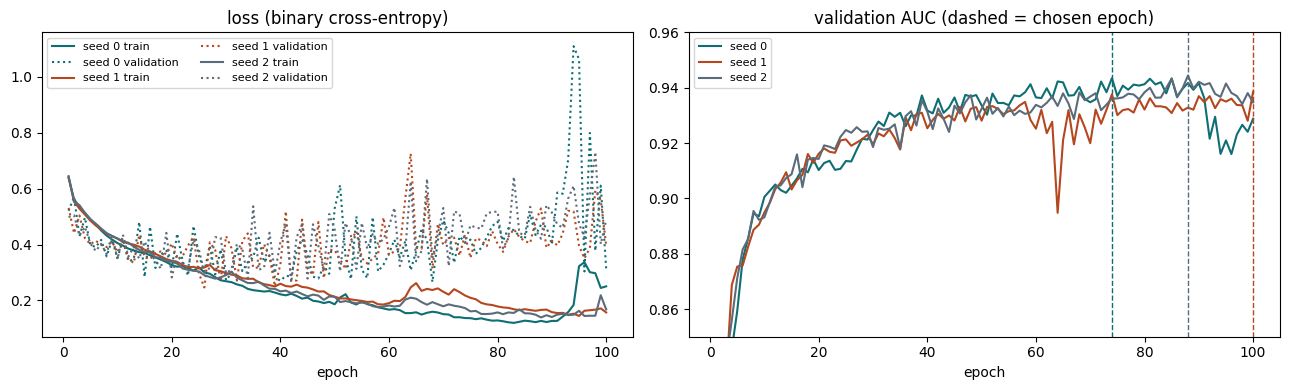

{'0': (0.6384, 0.2504, 74), '1': (0.641, 0.157, 100), '2': (0.6447, 0.1678, 88)} (first-epoch loss, last-epoch loss, chosen epoch)


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
colors = {"0": "#0E6E73", "1": "#B5471F", "2": "#5B6B7A"}
for s, h in hist["seeds"].items():
    ep = np.arange(1, len(h["train_loss"]) + 1)
    ax[0].plot(ep, h["train_loss"], color=colors[s], label=f"seed {s} train")
    ax[0].plot(ep, h["val_loss"], color=colors[s], ls=":", label=f"seed {s} validation")
    ax[1].plot(ep, h["val_auc"], color=colors[s], label=f"seed {s}")
    ax[1].axvline(h["best_epoch"], color=colors[s], ls="--", lw=1)
ax[0].set_title("loss (binary cross-entropy)"); ax[0].set_xlabel("epoch"); ax[0].legend(fontsize=8, ncol=2)
ax[1].set_title("validation AUC (dashed = chosen epoch)"); ax[1].set_xlabel("epoch"); ax[1].legend(fontsize=8)
ax[1].set_ylim(0.85, 0.96)
plt.tight_layout(); plt.show()
print({s: (h["train_loss"][0].__round__(4), h["train_loss"][-1].__round__(4), h["best_epoch"]) for s, h in hist["seeds"].items()},
      "(first-epoch loss, last-epoch loss, chosen epoch)")

## Test-set results (mean ± std over seeds)
Always predicting "normal" scores the majority accuracy below, so accuracy alone says little. `0.5` is the default cut-off; "validation-tuned" is the F1-maximising threshold chosen on the validation set.

In [4]:
def ms(v):
    v = np.asarray(v, dtype=float)
    return f"{v.mean():.3f} ± {v.std(ddof=1):.3f}"
by = {m: df[df.thr_mode == m] for m in ("@0.5", "+thr")}
table = pd.DataFrame({label: {"threshold 0.5": ms(by["@0.5"][k]), "validation-tuned": ms(by["+thr"][k])} for k, label in METRIC_COLS}).T
table.loc["decision threshold"] = ["0.50", ms(by["+thr"]["thr"])]
display(table)
r0 = df.iloc[0]
print(f"test set: {r0.tp + r0.tn + r0.fp + r0.fn} rows, {r0.tp + r0.fn} attacks ({r0.n_spoofing} Spoofing + {r0.n_data_alteration} Data Alteration)")
print(f"always-predict-normal accuracy: {r0.majority_acc:.4f}")
print("test set scored", sorted(df.test_calls.unique()), "time(s) per seed; epochs run:", sorted(df.epochs_run.unique()),
      "| train seconds per seed:", sorted(df.drop_duplicates('seed').train_seconds.round(1)))

,threshold 0.5,validation-tuned
accuracy,0.864 ± 0.021,0.930 ± 0.004
precision,0.479 ± 0.041,0.718 ± 0.022
recall,0.883 ± 0.022,0.725 ± 0.005
F1,0.621 ± 0.033,0.721 ± 0.013
macro-F1,0.769 ± 0.024,0.841 ± 0.008
normal-class recall,0.861 ± 0.026,0.959 ± 0.004
AUC,0.949 ± 0.002,0.949 ± 0.002
recall Spoofing,0.760 ± 0.045,0.434 ± 0.010
recall Data Alteration,1.000 ± 0.000,1.000 ± 0.000
decision threshold,0.50,0.923 ± 0.035


test set: 3263 rows, 409 attacks (199 Spoofing + 210 Data Alteration)
always-predict-normal accuracy: 0.8747
test set scored [np.int64(1)] time(s) per seed; epochs run: [np.int64(100)] | train seconds per seed: [3.7, 5.2, 5.6]


## Per-seed results

In [5]:
display(df[["seed", "thr_mode", "thr", "acc", "prec", "rec", "f1", "macro_f1", "auc", "rec_spoofing", "rec_data_alteration",
            "best_epoch", "best_val_auc", "train_seconds"]].round(3).reset_index(drop=True))

,seed,thr_mode,thr,acc,prec,rec,f1,macro_f1,auc,rec_spoofing,rec_data_alteration,best_epoch,best_val_auc,train_seconds
0,0,@0.5,0.50,0.839,0.432,0.897,0.583,0.742,0.948,0.789,1.0,74,0.943,3.681
1,0,+thr,0.96,0.932,0.732,0.726,0.729,0.845,0.948,0.437,1.0,74,0.943,3.681
2,1,@0.5,0.50,0.874,0.499,0.858,0.631,0.777,0.949,0.709,1.0,100,0.939,5.184
3,1,+thr,0.89,0.925,0.693,0.719,0.706,0.831,0.949,0.422,1.0,100,0.939,5.184
4,2,@0.5,0.50,0.878,0.508,0.895,0.648,0.787,0.951,0.784,1.0,88,0.944,5.595
5,2,+thr,0.92,0.932,0.730,0.729,0.729,0.845,0.951,0.442,1.0,88,0.944,5.595


## Confusion matrix (test set, mean over the 3 seeds)
Rows are the actual class, columns the prediction.

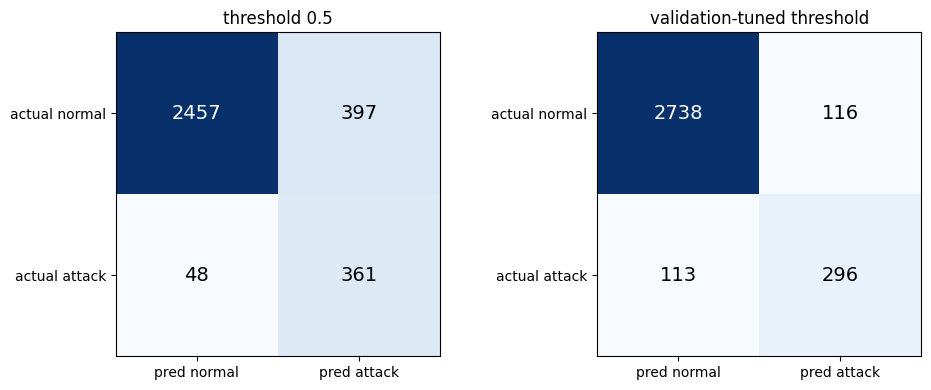

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (m, title) in zip(ax, (("@0.5", "threshold 0.5"), ("+thr", "validation-tuned threshold"))):
    d = by[m]
    cm = np.array([[d.tn.mean(), d.fp.mean()], [d.fn.mean(), d.tp.mean()]])
    a.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{cm[i, j]:.0f}", ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
    a.set_xticks([0, 1]); a.set_xticklabels(["pred normal", "pred attack"]); a.set_yticks([0, 1]); a.set_yticklabels(["actual normal", "actual attack"])
    a.set_title(title)
plt.tight_layout(); plt.show()

## Which attacks are missed?
The test set has two attack types. Recall is computed on each separately.

In [7]:
display(pd.DataFrame({"threshold 0.5": [ms(by["@0.5"].rec_spoofing), ms(by["@0.5"].rec_data_alteration)],
                      "validation-tuned": [ms(by["+thr"].rec_spoofing), ms(by["+thr"].rec_data_alteration)]},
                     index=[f"Spoofing (n={r0.n_spoofing})", f"Data Alteration (n={r0.n_data_alteration})"]))

,threshold 0.5,validation-tuned
Spoofing (n=199),0.760 ± 0.045,0.434 ± 0.010
Data Alteration (n=210),1.000 ± 0.000,1.000 ± 0.000
